# Automated ML Pipeline

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

## Config code 
 

In [2]:
FILE_PATH = "../Data/Pipeline_data/Regression/housing/housing.csv"

if "_target_cache" not in globals():
    _target_cache = {'path': None, 'target': None, 'task': None}

def load_data(file_path):
    if not os.path.isfile(file_path):
        raise FileNotFoundError(f"File not found: {file_path}")
    return pd.read_csv(file_path)

def ask_target(df):
    print("Columns:",list(df.columns))
    while True:
        target = input("Enter the target column").strip()
        if target in df.columns:
            return target
        print(f"'{target}' not found. Try again.")

def get_target(df, file_path):
    if _target_cache['path'] == file_path and _target_cache['target'] in df.columns:
        print(f"Same file, reusing target: {_target_cache['target']}")
        return _target_cache['target']
    target = ask_target(df)
    _target_cache.update({'path': file_path, 'target': target, 'task': None})
    return  target

df = load_data(FILE_PATH)
TARGET = get_target(df, FILE_PATH)

Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


## Inspection 

In [3]:
def inspection(df):
    # checking the shape of data 
    print(f"rows: {df.shape[0]} \ncolumns: {df.shape[1]}\n")

    # checking for numerical and string columns
    num_col = df.select_dtypes(include='number').columns.tolist()
    string_col = df.select_dtypes(include=['object', 'string']).columns.tolist()
    print(f'Numerical Columns: {num_col} \nString Columns: {string_col}\n')

    # missing value percentage
    percentage = (df.isna().mean() * 100).round(3).to_dict()
    null_pct = {col: pct for col, pct in percentage.items() if pct > 0}
    if not null_pct:
        print("Null Values: 0%\n")
    else:
        for col, pct in null_pct.items():
            print(f"{col}: {pct}%\n")

    # Unique Value count per column
    unique_val = df[string_col].nunique().to_dict()
    for col, val in unique_val.items():
        print(f"{col} unique values: {val}") # \n here add new line after execution of for loop every time
    print('') # adds an empty line \n not used because it add 2 empty rows 
  
    # duplicate rows
    print(f"Duplicate rows: {df.duplicated().sum()}\n")

    # constant columns
    constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) == 1]
    print(f"Constant columns: {constant_cols if constant_cols else 'None'}")

inspection(df)

rows: 20640 
columns: 10

Numerical Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value'] 
String Columns: ['ocean_proximity']

total_bedrooms: 1.003%

ocean_proximity unique values: 5

Duplicate rows: 0

Constant columns: None


Target 'median_house_value' is numeric (float64)

count : 20640.0
mean : 206855.817
std : 115395.616
min : 14999.0
25% : 119600.0
50% : 179700.0
75% : 264725.0
max : 500001.0

Skewness of 'median_house_value': 0.978 (moderately skewed)


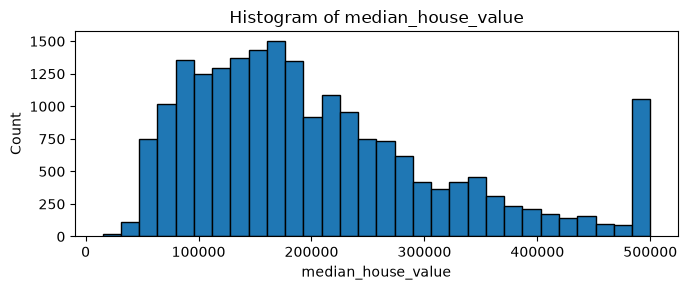

In [4]:
def target_check(df, target):
    # data type
    # this prints the data type of the target 
    kind = df[target].dtype.kind 
    if kind in 'iuf':
        print(f"Target '{target}' is numeric ({df[target].dtype})\n")
    elif kind in 'OU':
        print(f"Target '{target}' is string ({df[target].dtype})\n")
    else:
        print(f"Target '{target}' is non numeric ({df[target].dtype})\n")

    # describe the target 
    # this code store the values of describing the target to a dict with round value upto 3 
    if kind in 'iuf':
        desc_data = df[target].describe().round(3).to_dict()
        for desc, val in desc_data.items():
            print(f"{desc} : {val}")
        print('') # this only add an empty line 

    # first check if the target is numeric or not and the unique values
    if kind in 'iuf' and df[target].nunique() > 10:
        # skewness
        # this calculate the skewness of the target and tells if the target is how much skewed 
        skewness = df[target].skew()
        if abs(skewness) <=0.5:
            label = 'roughly symmetric'
        elif abs(skewness) <=1:
            label = 'moderately skewed'
        else:
            label = 'strongly skewed'
        print(f"Skewness of '{target}': {skewness:.3f} ({label})")

    # first check for numeric values
    if kind in 'iuf':
        fig, axes = plt.subplots(figsize=(7, 3))
        axes.hist(df[target].dropna(), bins=30, edgecolor='black')
        axes.set_title(f"Histogram of {target}")
        axes.set_xlabel(target)
        axes.set_ylabel("Count")
        plt.tight_layout()
        plt.show()
    else:
        print("Skipping plots: target is not numeric")
    

target_check(df, TARGET)

## Regression Or Classification

In [5]:
def confirm(message):
        return input(f"{message} Continue? (y/n):").strip().lower() == 'y'

def ask_task():
        while True:
                choice = input("Enter task type (r = regression, c = classification):").strip().lower()
                if choice in ('r', 'regression'):
                        return 'regression'
                if choice in ('c', 'classification'):
                        return 'classification'
                print(f"'{choice}' is invalid. Enter r or c")

def get_task_type(df, target, warn_unique):
        if _target_cache['task'] is not None:
                print(f"Same file and target, reusing task type: {_target_cache['task']}")
                return _target_cache['task']
        
        series = df[target]
        is_numeric = series.dtypes.kind in 'iuf'
        n_unique = series.nunique()

def check_regression_choice(series, warn_unique):
        if series.dtype.kind not in 'iuf':
                print(f"Hard Warning: regression needs numeric target, but {series.name} is {series.dtype}")
                return False
        n_unique = series.nunique()
        if n_unique <= warn_unique:
                return confirm(f"SOFT WARNING: target has only {n_unique} unique values, which looks like classification.")
        return True

def check_classification_choice(series, warn_unique):
        if series.dtype.kind == 'f':
                if not confirm(f"SOFT WARNING: target is float ({series.dtype}), which looks like regression."):
                        return False
        if series.dtype.kind in 'iuf' and series.nunique() > warn_unique:
                return confirm(f"SOFT WARNING: target has {series.nunique()} unique values, which looks like regression.")
        return True

def get_task_type(df, target, warn_unique = 10):
        if _target_cache['task'] is not None:
                print(f"Same file and target, reusing the task type : {_target_cache['task']}")
                return _target_cache['task']
        series = df[target]
        while True:
                task = ask_task()
                if task == 'regression' and not check_regression_choice(series, warn_unique):
                        continue
                if task == 'classification' and not check_classification_choice(series, warn_unique):
                        continue

                _target_cache['task'] = task
                print(f"Task type set: {task}")
                return task

TASK = get_task_type(df, TARGET)

Task type set: regression


## Cleaning the data

In [6]:
def clean_data(df, target, missing_thresh = 0.5, id_ratio = 0.95):
    df = df.copy()
    report = {"initial_shape": df.shape}

    # drop rows with missing targets
    n = len(df)
    df = df.dropna(subset= [target])
    report['rows_dropped_missing_target'] = n - len(df)

    # drop duplicate rows
    n = len(df)
    df = df.drop_duplicates()
    report['duplicated_rows_dropped'] = n - len(df)

    feats = [c for c in df.columns if c != target]

    # drop column missing the threshold 
    high_missing_cols = [c for c in feats if df[c].isna().mean() > missing_thresh]
    df = df.drop(columns= high_missing_cols)
    report['high_missing_col'] = high_missing_cols
    feats = [c for c in feats if c not in high_missing_cols]

    # drop id-like columns
    id_cols = [
        c for c in feats
        if df[c].dtype.kind != 'f' and df[c].nunique() / len(df) >= id_ratio
    ]
    df = df.drop(columns = id_cols)
    report['drop_id_like_columns'] = id_cols
    feats = [c for c in feats if c not in id_cols]

    # drop duplicate columns
    dup_mask = df[feats].T.duplicated()
    dup_cols = dup_mask[dup_mask].index.tolist()
    df = df.drop(columns = dup_cols)
    report['duplicated_columns'] = dup_cols

    # final report
    report["final_shape"] = df.shape
    return df, report

df_clean, clean_report = clean_data(df, TARGET)
clean_report

{'initial_shape': (20640, 10),
 'rows_dropped_missing_target': 0,
 'duplicated_rows_dropped': 0,
 'high_missing_col': [],
 'drop_id_like_columns': [],
 'duplicated_columns': [],
 'final_shape': (20640, 10)}